# Laplace Transforms with SymPy

Laplace transforms turn linear differential equations into algebraic equations, which is especially handy when the independent variable appears inside complicated functions. This notebook uses **SymPy** to compute transforms and inverse transforms.

$$\mathcal{L}\{f(t)\} = F(p) = \int_0^\infty f(t)\,e^{-pt}\,dt$$

This block of code sets up the needed modules and defines the symbols t and p that we use for Laplace Transforms. Run it before anything else.

In [1]:
import sympy as sp
from sympy import exp, cos, sin, laplace_transform, inverse_laplace_transform, Eq, symbols
sp.init_printing()

t = symbols('t', positive=True)
p = symbols('p')

## Examples

These two examples show code for taking Laplace transform and Inverse Laplace Transform

**Transform of** $e^{-2t}$. `noconds=True` returns just the expression, without the convergence conditions.

In [3]:
f = exp(-2*t)
F = laplace_transform(f, t, p, noconds=True)
F

**Inverse transform of** $\dfrac{4}{p^2+4}$ 

In [4]:
F = 4/(p**2 + 4)
f = inverse_laplace_transform(F, p, t)
f

---
## Problem 1: Transform of $t\,e^{-2t}\cos(3t)$

In [ ]:
f = # fill in the function you want to take the Laplace transform of
F = sp.simplify(laplace_transform(f, t, p, noconds=True))
F

---
## Problem 2: Inverse transform of $\dfrac{5-2p}{p^2-p-2}$

In [ ]:
F = # fill in the function you want to take the inverse Laplace transform of
f = inverse_laplace_transform(F, p, t)
f

You can use the simplify function to make this more compact:

In [ ]:
sp.simplify(f)

---
## Problem 3: Solve with Laplace transforms

$$y''+4y=\sin(2t),\qquad y(0)=10,\quad y'(0)=0$$

**Step 1.** Transform both sides using
$\mathcal{L}\{y''\}=p^2Y-p\,y(0)-y'(0)$, $\mathcal{L}\{y\}=Y$,
<br> and 
use the code below  to get $\mathcal{L}\{\sin 2t\}=F$

In [ ]:
f = # fill in the function you want to take the Laplace transform of
F = sp.simplify(laplace_transform(f, t, p, noconds=True))
F

**Step 2.** You should now have an algebraic equation for Y and s. Solve solve this for $Y$ in terms of $s$. 

In [ ]:
Y = # fill in the algebraic expression for Y(s) in terms of s
display(Y)
display(sp.simplify(Y))

**Step 3.** Now take the inverse Laplace Transform of Y to get $y(t)$.

In [ ]:
y = sp.simplify(inverse_laplace_transform(Y, p, t))
display(y)

**Answer:**

You should get:
$$y(t)=10\cos 2t+\frac{\sin 2t-2t\cos 2t}{8}$$

The $-\tfrac{t}{4}\cos 2t$ term grows without bound because the forcing frequency equals the natural frequency of the system (**resonance**).

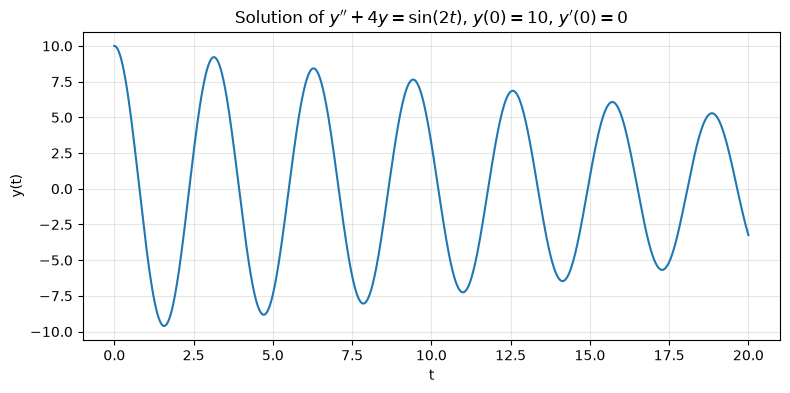

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

yf = sp.lambdify(t, y, 'numpy')
tt = np.linspace(0, 20, 1000)

plt.figure(figsize=(9, 4))
plt.plot(tt, yf(tt))
plt.xlabel('t'); plt.ylabel('y(t)')
plt.title(r"Solution of $y''+4y=\sin(2t)$, $y(0)=10$, $y'(0)=0$")
plt.grid(alpha=0.3)
plt.show()